# Task 1: Confusion Matrix and ROC Curve
Create a confusion matrix and ROC curve, interpret misclassifications, optimize the decision threshold and compare models on their ability to separate High and Low satisfaction.

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)

## Step 2: Load and prepare the data

In [2]:
df = pd.read_csv("employee_data_1.csv")

# fill missing values with median
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].median())

# target: High = 1, Low = 0
df["Satisfaction"] = df["Satisfaction"].map({"Low": 0, "High": 1})

# text columns -> numbers
df = pd.get_dummies(df, columns=["Department", "Education", "City_Tier"], drop_first=True)

X = df.drop("Satisfaction", axis=1)
y = df["Satisfaction"]
print("Features:", X.shape[1])
df.head()

Features: 18


,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,Education_Masters,Education_PhD,City_Tier_Tier2,City_Tier_Tier3
0,41,17,2.4,42.0,56.0,0,5.0,25.00,1,False,False,True,False,False,False,False,True,True,False
1,39,13,3.7,49.0,12.0,2,3.1,19.41,0,False,False,False,False,True,False,False,False,False,False
2,24,2,3.5,45.0,8.0,2,3.9,8.41,0,False,False,False,True,False,True,False,False,False,True
3,26,0,3.7,34.0,5.0,1,4.0,19.83,0,True,False,False,False,False,False,True,False,False,False
4,44,19,3.8,40.0,56.0,0,3.2,28.35,1,False,False,False,False,False,False,False,False,True,False


## Step 3: Split and scale the data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SVM and Logistic Regression need scaled data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn scaling only from train data
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (1600, 18)  Test: (400, 18)


## Step 4: Train three models
I will compare Logistic Regression, Random Forest and SVM. `predict_proba` gives the probability of High satisfaction, which is needed for the ROC curve and thresholds.

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
}

probs = {}   # to store predicted probabilities
for name, model in models.items():
    model.fit(X_train_s, y_train)
    probs[name] = model.predict_proba(X_test_s)[:, 1]
    print(name, "trained")

Logistic Regression trained


Random Forest trained


SVM trained


## Step 5: Confusion matrix (default threshold = 0.5)

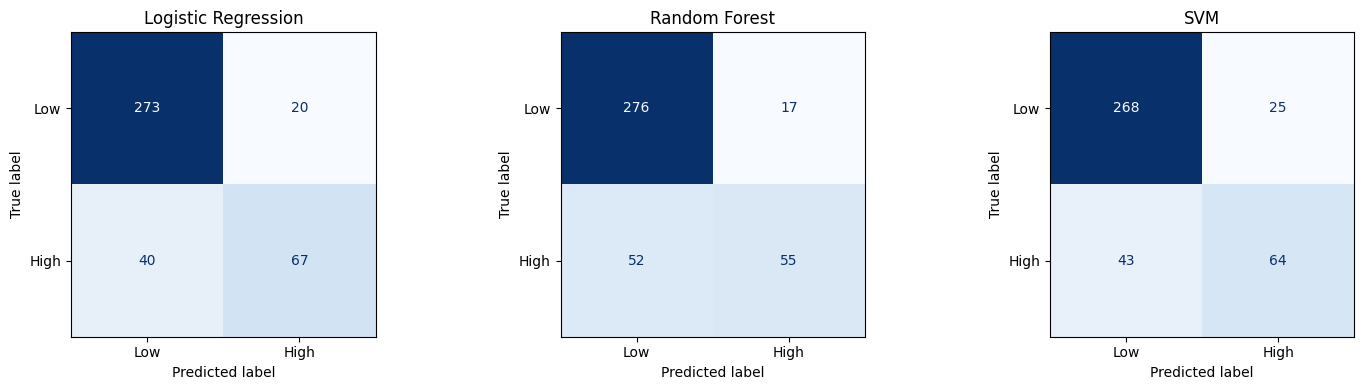

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, p) in zip(axes, probs.items()):
    y_pred = (p >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Low", "High"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In the confusion matrix, **False Negatives** (actual High but predicted Low) are the main problem because the High class is small. Logistic Regression catches the most High employees at threshold 0.5.

## Step 6: ROC curve and AUC for all models

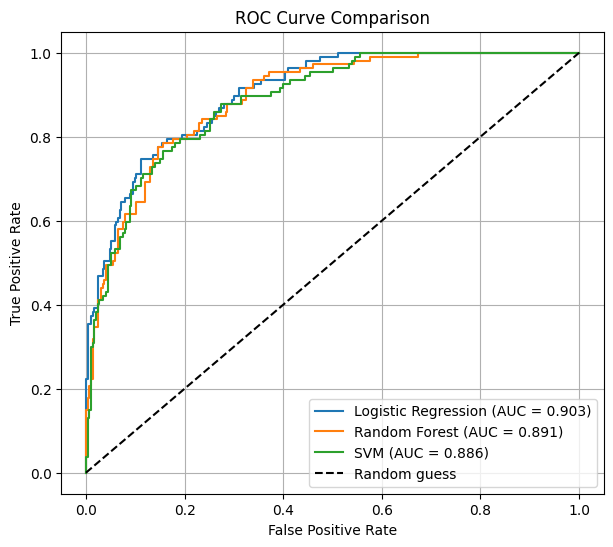

In [6]:
plt.figure(figsize=(7, 6))

for name, p in probs.items():
    fpr, tpr, thresholds = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

## Step 7: Compare the models (threshold = 0.5)

In [7]:
rows = []
for name, p in probs.items():
    y_pred = (p >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, p),
    })

compare_df = pd.DataFrame(rows).set_index("Model")
compare_df.round(4)

,Accuracy,Precision,Recall,F1-score,AUC
Model,,,,,
Logistic Regression,0.8500,0.7701,0.6262,0.6907,0.9027
Random Forest,0.8275,0.7639,0.5140,0.6145,0.8907
SVM,0.8300,0.7191,0.5981,0.6531,0.8857


## Step 8: Interpret the misclassifications
I take the best model (highest AUC) and look at the wrongly predicted employees.

In [8]:
best_name = compare_df["AUC"].idxmax()
print("Best model by AUC:", best_name)

best_prob = probs[best_name]
y_pred_best = (best_prob >= 0.5).astype(int)

# put the results next to the original test data
result = X_test.copy()
result["Actual"] = y_test.values
result["Predicted"] = y_pred_best

fn = result[(result["Actual"] == 1) & (result["Predicted"] == 0)]   # missed High
fp = result[(result["Actual"] == 0) & (result["Predicted"] == 1)]   # wrongly High
tp = result[(result["Actual"] == 1) & (result["Predicted"] == 1)]   # correct High

print("False Negatives:", len(fn))
print("False Positives:", len(fp))
print("True Positives :", len(tp))

Best model by AUC: Logistic Regression
False Negatives: 40
False Positives: 20
True Positives : 67


In [9]:
cols = ["Age", "Experience_Years", "Salary_LPA", "Work_Life_Balance", "Weekly_Hours", "Training_Hours", "Performance_Rating"]

summary = pd.DataFrame({
    "Correct High (TP)": tp[cols].mean(),
    "Missed High (FN)": fn[cols].mean(),
    "Wrong High (FP)": fp[cols].mean(),
})
summary.round(2)

,Correct High (TP),Missed High (FN),Wrong High (FP)
Age,48.00,40.85,48.55
Experience_Years,23.75,15.80,24.45
Salary_LPA,35.36,23.91,32.26
Work_Life_Balance,4.17,3.67,3.89
Weekly_Hours,41.34,42.70,41.80
Training_Hours,38.37,41.78,40.05
Performance_Rating,3.80,3.53,3.45


Comparing the averages: the missed High employees (FN) have a much lower average salary (about 24 LPA vs 35 LPA for correctly found High employees) and fewer years of experience (about 16 vs 24). So the model mostly misses satisfied employees who look like the Low group (lower paid and less experienced). The wrongly predicted High employees (FP) look like the correct High ones (high experience and salary), so they are hard to tell apart.

## Step 9: Optimize the decision threshold
The default threshold is 0.5. I try many thresholds and see how precision, recall and F1 change.

In [10]:
thresholds = np.arange(0.1, 0.91, 0.05)
t_rows = []

for t in thresholds:
    y_pred = (best_prob >= t).astype(int)
    t_rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    })

t_df = pd.DataFrame(t_rows)
t_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.10,0.4608,0.9346,0.6173
1,0.15,0.5104,0.9159,0.6555
2,0.20,0.5380,0.8598,0.6619
3,0.25,0.5811,0.8037,0.6745
4,0.30,0.6296,0.7944,0.7025
5,0.35,0.6723,0.7477,0.7080
6,0.40,0.7054,0.7383,0.7215
7,0.45,0.7228,0.6822,0.7019
8,0.50,0.7701,0.6262,0.6907
9,0.55,0.7875,0.5888,0.6738


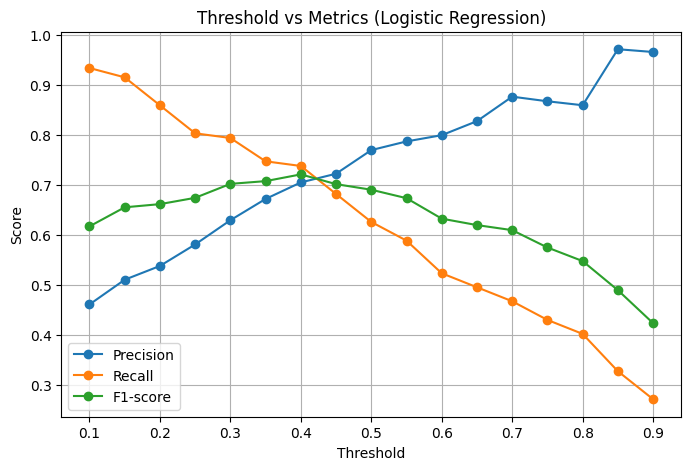

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(t_df["Threshold"], t_df["Precision"], marker="o", label="Precision")
plt.plot(t_df["Threshold"], t_df["Recall"], marker="o", label="Recall")
plt.plot(t_df["Threshold"], t_df["F1-score"], marker="o", label="F1-score")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title(f"Threshold vs Metrics ({best_name})")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
best_row = t_df.loc[t_df["F1-score"].idxmax()]
best_t = best_row["Threshold"]
print("Best threshold (highest F1):", best_t)
print(best_row.round(4))

Best threshold (highest F1): 0.4
Threshold    0.4000
Precision    0.7054
Recall       0.7383
F1-score     0.7215
Name: 6, dtype: float64


## Step 10: Confusion matrix before and after the new threshold

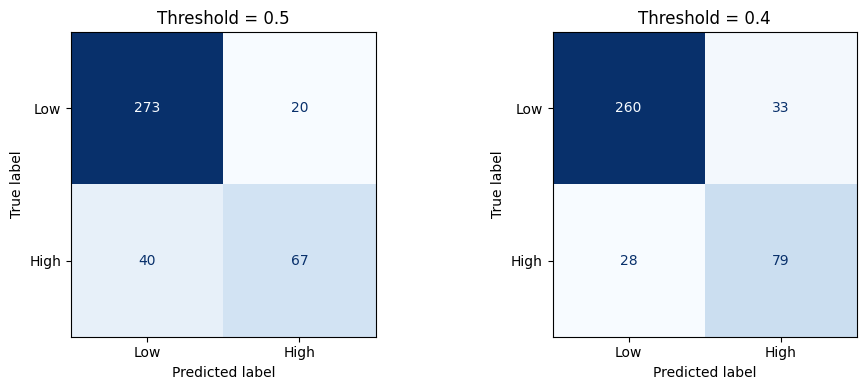

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, (best_prob >= 0.5).astype(int)),
                       display_labels=["Low", "High"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Threshold = 0.5")

ConfusionMatrixDisplay(confusion_matrix(y_test, (best_prob >= best_t).astype(int)),
                       display_labels=["Low", "High"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"Threshold = {best_t}")

plt.tight_layout()
plt.show()

## Conclusion
- Logistic Regression has the highest AUC (about 0.90), followed by Random Forest and SVM (all close together), so it separates High and Low satisfaction best.
- With the default threshold of 0.5 the best model misses 40 of the 107 High employees (false negatives) because the data is imbalanced.
- Lowering the threshold to 0.4 raised recall from about 0.63 to 0.74 and F1 from about 0.69 to 0.72, with precision dropping from about 0.77 to 0.71.
- So the threshold should be chosen based on what matters more: finding all satisfied employees or avoiding false alarms.